# Practical 6 — Large language model + LoRA
## Twitter Financial News: is a market tweet bearish, bullish or neutral?

**Assignment 4** · Aziz Abdulin · repeats the course practical on adapting an LLM with LoRA on a new dataset.

**Dataset.** Twitter Financial News Sentiment (zeroshot, 2022; MIT licence): 11,931 English finance tweets labelled
*bearish* (negative for a stock), *bullish* (positive) or *neutral*. The official split has 9,543 training and 2,388
validation tweets; the official validation set is used here as the **test set**, and 1,000 training tweets are held
out as validation. Classes are imbalanced: 65 % neutral.

**Model.** Qwen2.5-0.5B — a 494 M-parameter decoder-only language model (Apache-2.0). The notebook was executed on a
Kaggle T4 GPU (16 GB) through the Kaggle API; on a 16 GB laptop the model in fp32 exhausts the memory.

**Three ways to use the same LLM**, from no training to adaptation:

1. **Zero-shot prompting** — ask the base model to name the sentiment; nothing is trained.
2. **Frozen LLM + linear classifier** — the LLM turns every tweet into a vector (mean of the last hidden layer); only a
   linear layer is trained (transfer learning).
3. **LoRA fine-tuning** — low-rank adapters are added to the attention and MLP projections of every layer and trained
   together with a new classification head; the 494 M original weights stay frozen.

Metric: **macro-F1** (the mean of the per-class F1 scores), so that the two smaller classes count as much as neutral.

In [1]:
import json, math, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fn
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from transformers.utils import logging as hf_logging
from peft import LoraConfig, get_peft_model
from a4_metrics import accuracy, macro_f1, f1_per_class, confusion, bootstrap_ci

hf_logging.set_verbosity_error()
SEED, MODEL, MAX_LEN = 42, "Qwen/Qwen2.5-0.5B", 64
torch.manual_seed(SEED); np.random.seed(SEED)
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
URL = "https://huggingface.co/api/datasets/zeroshot/twitter-financial-news-sentiment/parquet/default/{}/0.parquet"
for s in ("train", "validation"):
    f = DATA / f"fin_tweets_{s}.parquet"
    if not f.exists(): urllib.request.urlretrieve(URL.format(s), f)
pool = pd.read_parquet(DATA / "fin_tweets_train.parquet"); test = pd.read_parquet(DATA / "fin_tweets_validation.parquet")
rng = np.random.default_rng(SEED)
val_idx = np.concatenate([rng.permutation(np.where(pool.label == c)[0])[:round(1000 * (pool.label == c).mean())] for c in range(3)])
val, train = pool.iloc[np.sort(val_idx)].reset_index(drop=True), pool.drop(index=val_idx).reset_index(drop=True)
LABELS = ["bearish", "bullish", "neutral"]
print("device:", DEV)
print(pd.DataFrame({s: d.label.value_counts().sort_index().values for s, d in [("train", train), ("validation", val), ("test", test)]}, index=LABELS))
train.head(4)

device: cuda
         train  validation  test
bearish   1291         151   347
bullish   1721         202   475
neutral   5531         647  1566


,text,label
0,$BYND - JPMorgan reels in expectations on Beyo...,0
1,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0
2,$ESS: BTIG Research cuts to Neutral https://t....,0
3,$FNKO - Funko slides after Piper Jaffray PT cu...,0


In [2]:
tok = AutoTokenizer.from_pretrained(MODEL)
lens = [len(tok(t).input_ids) for t in train.text[:2000]]
print(f"tokens per tweet: median {int(np.median(lens))}, 99th percentile {int(np.percentile(lens, 99))}; MAX_LEN = {MAX_LEN}")
results, preds = {}, {}
def report(name, y, p, extra=None):
    lo, hi = bootstrap_ci(y, p, lambda a, b: macro_f1(a, b, 3))
    results[name] = {"test accuracy": accuracy(y, p), "test macro-F1": macro_f1(y, p, 3), "95 % CI (macro-F1)": f"[{lo:.3f}, {hi:.3f}]",
                     **{f"F1 {l}": f for l, f in zip(LABELS, f1_per_class(y, p, 3))}, **(extra or {})}
    preds[name] = p
    print(name, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in results[name].items()})

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

tokens per tweet: median 22, 99th percentile 52; MAX_LEN = 64


## 1. Zero-shot prompting

The base model reads the prompt below and the next-token probabilities of the three label words are compared; the
most probable word is the prediction. A constant baseline (always "neutral") is shown for reference.

```
Classify the sentiment of this financial news tweet for investors as negative, positive or neutral.
Tweet: <text>
Sentiment:
```

In [3]:
y_test = test.label.to_numpy()
report("always neutral", y_test, np.full(len(y_test), 2))
lm = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).to(DEV).eval()
words = [" negative", " positive", " neutral"]
word_ids = [tok(w, add_special_tokens=False).input_ids[0] for w in words]
print("label tokens:", [tok.decode([i]) for i in word_ids])
tok.padding_side = "left"
prompt = "Classify the sentiment of this financial news tweet for investors as negative, positive or neutral.\nTweet: {}\nSentiment:"
def zero_shot(texts, bs=32):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            b = tok([prompt.format(t) for t in texts[i:i + bs]], return_tensors="pt", padding=True).to(DEV)
            out.append(lm(**b).logits[:, -1, word_ids].float().cpu())
    return torch.cat(out)
t = time.time(); zs = zero_shot(list(test.text)); t_zs = time.time() - t
report("zero-shot prompting", y_test, zs.argmax(1).numpy(), {"trained weights": 0, "train min": 0.0})
print(f"{len(test)} tweets in {t_zs:.0f} s; predicted class shares:", np.bincount(zs.argmax(1).numpy(), minlength=3) / len(test))

always neutral {'test accuracy': 0.656, 'test macro-F1': 0.264, '95 % CI (macro-F1)': '[0.259, 0.268]', 'F1 bearish': np.float64(0.0), 'F1 bullish': np.float64(0.0), 'F1 neutral': np.float64(0.792)}


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

label tokens: [' negative', ' positive', ' neutral']
zero-shot prompting {'test accuracy': 0.319, 'test macro-F1': 0.336, '95 % CI (macro-F1)': '[0.320, 0.351]', 'F1 bearish': np.float64(0.581), 'F1 bullish': np.float64(0.424), 'F1 neutral': np.float64(0.001), 'trained weights': 0, 'train min': 0.0}
2388 tweets in 49 s; predicted class shares: [2.78475712e-01 7.21105528e-01 4.18760469e-04]


## 2. Frozen LLM + linear classifier

Each tweet goes through the LLM once; the last hidden layer is averaged over the tokens (896 numbers). A linear layer
with class weights (inverse class frequency) is trained on the 8,543 training vectors; the weight decay is chosen on
validation.

In [4]:
tok.padding_side = "right"
def embed(texts, bs=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            b = tok(list(texts[i:i + bs]), return_tensors="pt", padding=True, truncation=True, max_length=MAX_LEN).to(DEV)
            h = lm(**b, output_hidden_states=True).hidden_states[-1]
            m = b.attention_mask.unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1)).float().cpu())
    return torch.cat(out)
t = time.time(); E = {s: embed(d.text) for s, d in [("train", train), ("val", val), ("test", test)]}; t_emb = time.time() - t
print(f"embedded {sum(len(e) for e in E.values()):,} tweets in {t_emb:.0f} s, vector size {E['train'].shape[1]}")
del lm
if DEV.type == "cuda": torch.cuda.empty_cache()

y_tr, y_va = torch.tensor(train.label.values), torch.tensor(val.label.values)
w_cls = torch.tensor(len(y_tr) / (3 * np.bincount(y_tr.numpy())), dtype=torch.float32)
mu, sd = E["train"].mean(0), E["train"].std(0) + 1e-6
def probe(wd, epochs=400):
    torch.manual_seed(SEED); head = nn.Linear(E["train"].shape[1], 3); opt = torch.optim.AdamW(head.parameters(), lr=1e-2, weight_decay=wd)
    for _ in range(epochs):
        loss = Fn.cross_entropy(head((E["train"] - mu) / sd), y_tr, weight=w_cls); opt.zero_grad(); loss.backward(); opt.step()
    return head
scores = {wd: macro_f1(y_va.numpy(), probe(wd)((E["val"] - mu) / sd).argmax(1).numpy(), 3) for wd in [1e-3, 1e-2, 1e-1, 1.0]}
best_wd = max(scores, key=scores.get); head = probe(best_wd)
print("validation macro-F1 by weight decay:", {k: round(v, 3) for k, v in scores.items()}, "-> chosen", best_wd)
report("frozen LLM + linear", y_test, head((E["test"] - mu) / sd).argmax(1).numpy(),
       {"trained weights": sum(p.numel() for p in head.parameters()), "train min": round(t_emb / 60, 1)})

embedded 11,931 tweets in 197 s, vector size 896
validation macro-F1 by weight decay: {0.001: 0.722, 0.01: 0.723, 0.1: 0.722, 1.0: 0.726} -> chosen 1.0
frozen LLM + linear {'test accuracy': 0.766, 'test macro-F1': 0.715, '95 % CI (macro-F1)': '[0.692, 0.736]', 'F1 bearish': np.float64(0.632), 'F1 bullish': np.float64(0.673), 'F1 neutral': np.float64(0.839), 'trained weights': 2691, 'train min': 3.3}


## 3. LoRA fine-tuning

**Configuration.**

| Parameter | Value | Why |
|---|---|---|
| rank `r` | 16 | enough capacity for a 3-class task; 8 is often too little for a new task, 64 adds memory with little gain |
| `lora_alpha` | 32 (= 2r) | scaling factor α/r = 2, the usual choice |
| `lora_dropout` | 0.05 | light regularisation of the adapters |
| target modules | `q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj` | adapters on every linear projection come closest to full fine-tuning |
| head | new 3-class linear layer `score`, trained fully | it is new, nothing to preserve |
| optimiser | AdamW, lr 2e-4, weight decay 0.01 | adapters need a larger step than full fine-tuning |
| schedule | 5 % linear warm-up, cosine decay | |
| batch, epochs | 16, 2 | |
| loss | cross-entropy with class weights | the two minority classes matter for macro-F1 |
| training data | all 8,543 training tweets | the run is on a Kaggle T4 GPU, so there is no need to subsample |

Each adapter adds two small matrices *A* (d_in × r) and *B* (r × d_out); their product, scaled by α/r, is added to the
frozen weight. *B* starts at zero, so training starts exactly from the pre-trained model.

In [5]:
EPOCHS, BS = 2, 16
sub = train.sample(frac=1, random_state=SEED).reset_index(drop=True)
torch.manual_seed(SEED)
clf = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3, dtype=torch.float32)
clf.config.pad_token_id = tok.pad_token_id
cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="SEQ_CLS", modules_to_save=["score"],
                 target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
clf = get_peft_model(clf, cfg).to(DEV)
n_train = sum(p.numel() for p in clf.parameters() if p.requires_grad); n_all = sum(p.numel() for p in clf.parameters())
print(f"trainable {n_train:,} of {n_all:,} parameters ({100 * n_train / n_all:.2f} %)")

def batches(df, bs, shuffle=False):
    idx = np.random.default_rng(SEED).permutation(len(df)) if shuffle else np.arange(len(df))
    for i in range(0, len(df), bs):
        b = df.iloc[idx[i:i + bs]]
        enc = tok(list(b.text), return_tensors="pt", padding=True, truncation=True, max_length=MAX_LEN)
        yield {k: v.to(DEV) for k, v in enc.items()}, torch.tensor(b.label.values, device=DEV)
def predict(model, df, bs=64):
    model.eval(); out = []
    with torch.no_grad():
        for x, _ in batches(df, bs): out.append(model(**x).logits.float().cpu())
    return torch.cat(out)

wts = torch.tensor(len(sub) / (3 * np.bincount(sub.label)), dtype=torch.float32, device=DEV)
opt = torch.optim.AdamW([p for p in clf.parameters() if p.requires_grad], lr=2e-4, weight_decay=0.01)
steps = EPOCHS * math.ceil(len(sub) / BS); warm = max(1, int(0.05 * steps))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (steps - warm))))
log, step, t0 = [], 0, time.time()
for ep in range(EPOCHS):
    clf.train()
    for x, y in batches(sub, BS, shuffle=True):
        loss = Fn.cross_entropy(clf(**x).logits.float(), y, weight=wts)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(clf.parameters(), 1.0); opt.step(); sched.step(); step += 1
        if step % 25 == 0: log.append({"step": step, "loss": loss.item(), "minutes": (time.time() - t0) / 60})
    f1v = macro_f1(val.label.values, predict(clf, val).argmax(1).numpy(), 3)
    log.append({"step": step, "epoch": ep + 1, "val macro-F1": f1v, "minutes": (time.time() - t0) / 60})
    print(f"epoch {ep + 1}: validation macro-F1 {f1v:.3f}, {(time.time() - t0) / 60:.1f} min")
t_lora = time.time() - t0
print(f"training: {len(sub) * EPOCHS / t_lora:.1f} tweets per second")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable 8,800,896 of 502,836,352 parameters (1.75 %)
epoch 1: validation macro-F1 0.844, 4.2 min
epoch 2: validation macro-F1 0.858, 8.4 min
training: 33.8 tweets per second


LoRA (r = 16) {'test accuracy': 0.897, 'test macro-F1': 0.869, '95 % CI (macro-F1)': '[0.852, 0.884]', 'F1 bearish': np.float64(0.827), 'F1 bullish': np.float64(0.852), 'F1 neutral': np.float64(0.927), 'trained weights': 8800896, 'train min': 8.4}
inference: 69 tweets per second


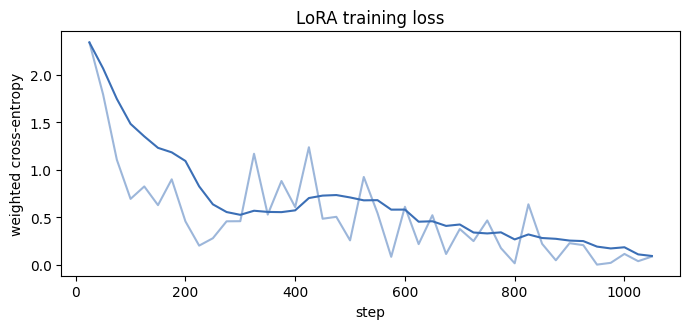

In [6]:
t = time.time(); logits = predict(clf, test); t_inf = time.time() - t
report("LoRA (r = 16)", y_test, logits.argmax(1).numpy(), {"trained weights": n_train, "train min": round(t_lora / 60, 1)})
print(f"inference: {len(test) / t_inf:.0f} tweets per second")
L = pd.DataFrame([r for r in log if "loss" in r])
fig, ax = plt.subplots(figsize=(7, 3.4)); ax.plot(L.step, L.loss, color="#3b6fb6", alpha=.5); ax.plot(L.step, L.loss.rolling(8, min_periods=1).mean(), color="#3b6fb6")
ax.set(xlabel="step", ylabel="weighted cross-entropy", title="LoRA training loss"); plt.tight_layout(); plt.savefig(FIG / "p6_loss.png", dpi=110); plt.show()

## 4. Comparison

In [7]:
res = pd.DataFrame(results).T
res.to_csv(RES / "p6_test.csv")
res

,test accuracy,test macro-F1,95 % CI (macro-F1),F1 bearish,F1 bullish,F1 neutral,trained weights,train min
always neutral,0.655779,0.264036,"[0.259, 0.268]",0.0,0.0,0.792109,NaN,NaN
zero-shot prompting,0.318677,0.335506,"[0.320, 0.351]",0.581028,0.424215,0.001276,0,0.0
frozen LLM + linear,0.766332,0.714747,"[0.692, 0.736]",0.632212,0.672986,0.839045,2691,3.3
LoRA (r = 16),0.896566,0.868704,"[0.852, 0.884]",0.827298,0.85189,0.926924,8800896,8.4


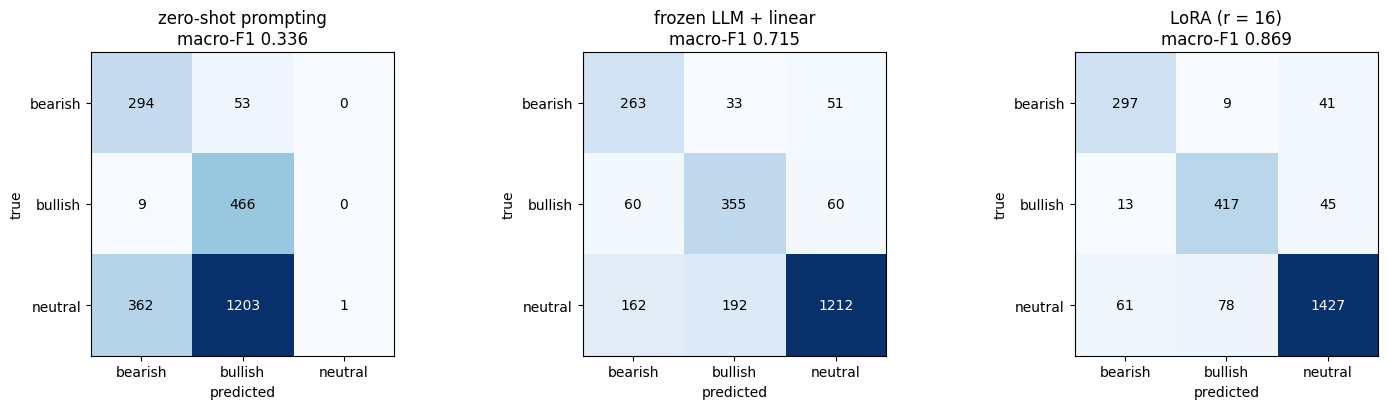

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, name in zip(ax, ["zero-shot prompting", "frozen LLM + linear", "LoRA (r = 16)"]):
    cm = confusion(y_test, preds[name], 3); a.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(3), LABELS); a.set_yticks(range(3), LABELS); a.set(title=f"{name}\nmacro-F1 {results[name]['test macro-F1']:.3f}", xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.savefig(FIG / "p6_confusion.png", dpi=110); plt.show()

**Why LoRA and not full fine-tuning** (memory without activations, fp32 training):

| | Full fine-tuning of 494 M | LoRA r = 16 (this notebook) |
|---|---|---|
| weights | 2.0 GB | 2.0 GB, frozen |
| gradients | 2.0 GB | only for the adapters |
| AdamW states | 4.0 GB | only for the adapters |
| total | ≈ 8 GB | ≈ 2.1 GB |
| saved result | 2 GB per task | tens of MB per task; one base model serves many adapters |

In [9]:
wrong = test.assign(pred=[LABELS[i] for i in preds["LoRA (r = 16)"]], true=[LABELS[i] for i in y_test])
wrong = wrong[wrong.pred != wrong.true]
pd.set_option("display.max_colwidth", 140)
print(f"LoRA errors: {len(wrong)} of {len(test)}")
wrong[["text", "true", "pred"]].head(10)

LoRA errors: 247 of 2388


,text,true,pred
0,$ALLY - Ally Financial pulls outlook https://t.co/G9Zdi1boy5,bearish,neutral
8,Barclays assigns only a 20% chance that studies on a Gilead antiviral drug being done in China will succeed against… https://t.co/lIgDhy...,bearish,neutral
9,BTIG points to breakfast pressure for Dunkin' Brands,bearish,neutral
12,Downgrades 4/7: $AAN $BDN $BECN $BTE $CDEV $CHK $COOP $CPE $CVA $DAN $DOC $DRH $EPR $ESRT $ETM $FAST $FBM $GM $GMS… https://t.co/CMXD50oQxI,bearish,neutral
39,$URBN - Urban Outfitters stands out in mall sector - BofA https://t.co/pvig3M420p,bullish,neutral
56,GE upgraded from Sell by longtime bear,bullish,bearish
61,Highlight: Edward Jones Sr. Equity Analyst Jennifer Roland on ExxonMobil reducing 2020 Capex by 30%: “Definitely a… https://t.co/dH0xlJujc1,bullish,neutral
92,AM Best Revises Outlooks to Stable for Sublimity Insurance Company https://t.co/WPcVIMko76 https://t.co/glnxmA3iIv,neutral,bullish
93,Analyst: Amazon Blocking FedEx Ground Good News For UPS,neutral,bearish
94,Analysts Expect Breakeven For China Online Education Group (NYSE:COE),neutral,bullish


In [10]:
json.dump({k: {kk: vv for kk, vv in v.items()} for k, v in results.items()} | {"_timing": {"zero_shot_s": t_zs, "embed_s": t_emb, "lora_s": t_lora,
           "inference_tweets_per_s": len(test) / t_inf, "trainable": n_train, "total": n_all}}, open(RES / "p6_summary.json", "w"), indent=1, default=float)

## 5. Conclusions

1. **The base model has the knowledge but is not a classifier.** Zero-shot prompting scores macro-F1 0.336 and only
   31.9 % accuracy — below "always neutral" (65.6 %), because the model said "neutral" for a single tweet out of 2,388.
   Yet on directional tweets it picks the right direction almost always (294 of 347 bearish and 466 of 475 bullish): a
   base language model prefers certain label words, so without instruction tuning or calibration its answers are biased.
2. **Transfer learning with a frozen LLM works.** Mean-pooled hidden states + a linear layer of 2,691 weights reach
   macro-F1 0.715 (accuracy 76.6 %); embedding all 11,931 tweets took 3.3 minutes on a T4.
3. **LoRA gives the best model by a wide margin:** macro-F1 0.869 (95 % CI [0.852, 0.884]), accuracy 89.7 %, +0.154
   over the frozen model. It trains 8.8 M of 502.8 M parameters (1.75 %) — two epochs over 8,543 tweets in 8.4 minutes —
   and reaches F1 0.83 / 0.85 / 0.93 for bearish / bullish / neutral.
4. **Why LoRA rather than full fine-tuning:** about 2.1 GB of training memory instead of ≈ 8 GB, a ≈ 35 MB adapter
   instead of a 2 GB copy of the model, and the base model stays untouched for other tasks.
5. **Remaining errors are about neutrality, not direction:** 225 of the 247 LoRA errors involve the neutral class (e.g.
   analyst notes and outlook changes that annotators read as directional); bearish and bullish are confused only 22 times.
6. **Compute:** the 0.5 B model in fp32 overloaded a 16 GB laptop, so the notebook was executed on a free Kaggle T4 GPU
   through the Kaggle API (`kaggle_p6.py`).